# Academic Survival Longitudinal Data Analysis

Exploratory analysis of `academic_survival_longitudinal (1).csv` using pandas and matplotlib.

Dataset: longitudinal student records with 22 columns (Student_ID through Censored), multiple semesters per student.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)


In [2]:
# Load the CSV file
df = pd.read_csv('academic_survival_longitudinal (1).csv')

# Preview the first rows
df.head()


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,0.0,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,0.0,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,0.0,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,0.0,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,0.0,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1


In [3]:
# Dataset shape and column info
print('Shape:', df.shape)
print()
df.info()

# Summary statistics
df.describe(include='all')


Shape: (79239, 22)

<class 'pandas.DataFrame'>
RangeIndex: 79239 entries, 0 to 79238
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Student_ID               79239 non-null  str    
 1   Age                      79239 non-null  int64  
 2   Gender                   79239 non-null  str    
 3   First_Generation         79239 non-null  int64  
 4   Family_Income            75635 non-null  float64
 5   Household_Size           79239 non-null  int64  
 6   Housing_Status           79239 non-null  str    
 7   Scholarship              79239 non-null  int64  
 8   Tuition_Base             79239 non-null  int64  
 9   Semester                 79239 non-null  int64  
 10  Course_Load              79239 non-null  int64  
 11  Work_Hours               79239 non-null  float64
 12  Emergency_Expense        79239 non-null  float64
 13  Sem_GPA                  79239 non-null  float64
 14  Attendance   

,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Emergency_Expense,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored
count,79239,79239.000000,79239,79239.000000,75635.000000,79239.000000,79239,79239.000000,79239.000000,79239.000000,...,79239.000000,79239.000000,79239.000000,78372.000000,79239.000000,79239.000000,79239.000000,79239.000000,79239,79239.000000
unique,20000,NaN,8,NaN,NaN,NaN,3,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN
top,STU_00018,NaN,Female,NaN,NaN,NaN,On-Campus,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Enrolled,NaN
freq,8,NaN,38035,NaN,NaN,NaN,31315,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70354,NaN
mean,NaN,19.492005,NaN,0.327894,61518.384346,3.187547,NaN,0.277515,24775.110741,3.145673,...,200.496788,2.691463,85.081599,66.375670,0.477530,0.652494,2.578287,0.087293,NaN,0.140272
std,NaN,2.139140,NaN,0.469449,39661.166570,1.332861,NaN,0.447775,10794.899387,1.946207,...,724.400513,0.422692,6.415864,12.730793,0.671954,0.786066,1.817880,0.282266,NaN,0.347271
min,NaN,17.000000,NaN,0.000000,3000.000000,1.000000,NaN,0.000000,15000.000000,1.000000,...,0.000000,0.440000,-2.000000,12.000000,0.000000,0.000000,1.000000,0.000000,NaN,0.000000
25%,NaN,18.000000,NaN,0.000000,35000.000000,2.000000,NaN,0.000000,15000.000000,1.000000,...,0.000000,2.440000,81.200000,58.000000,0.000000,0.000000,1.000000,0.000000,NaN,0.000000
50%,NaN,19.000000,NaN,0.000000,52000.000000,3.000000,NaN,0.000000,25000.000000,3.000000,...,0.000000,2.700000,85.200000,66.000000,0.000000,0.000000,2.100000,0.000000,NaN,0.000000
75%,NaN,21.000000,NaN,1.000000,77000.000000,4.000000,NaN,1.000000,25000.000000,4.000000,...,0.000000,2.960000,89.200000,75.000000,1.000000,1.000000,3.400000,0.000000,NaN,0.000000


In [4]:
# Check for missing values per column
df.isnull().sum()


Student_ID                    0
Age                           0
Gender                        0
First_Generation              0
Family_Income              3604
Household_Size                0
Housing_Status                0
Scholarship                   0
Tuition_Base                  0
Semester                      0
Course_Load                   0
Work_Hours                    0
Emergency_Expense             0
Sem_GPA                       0
Attendance                    0
LMS_Logins                  867
Advising_Visits               0
Failed_Courses                0
Financial_Stress              0
Target_Dropout_Next_Sem       0
End_of_Semester_Status        0
Censored                      0
dtype: int64

In [5]:
# Map Gender to four standard categories: Female, Male, Others, Prefer not to say
df['Gender'] = df['Gender'].astype(str).str.strip().str.title()
gender_map = {
    'Female': 'Female', 'Male': 'Male', 'M': 'Male', 'F': 'Female',
    'Other': 'Others', 'Others': 'Others',
    'Prefer Not To Say': 'Prefer not to say',
}
df['Gender'] = df['Gender'].replace(gender_map)
df['Gender'] = df['Gender'].where(
    df['Gender'].isin(['Female', 'Male', 'Others', 'Prefer not to say']), 'Others'
)
df['Gender'].value_counts()


Gender
Female               39626
Male                 38059
Others                1125
Prefer not to say      429
Name: count, dtype: int64

In [6]:
# Handle negative Sem_GPA: flag invalid values (< 0), replace with NaN
df['sem_gpa_invalid'] = df['Sem_GPA'] < 0
print('Invalid (negative) Sem_GPA rows:')
print(df.loc[df['Sem_GPA'] < 0, ['Student_ID', 'Semester', 'Sem_GPA']])

df.loc[df['Sem_GPA'] < 0, 'Sem_GPA'] = np.nan
df['Sem_GPA'] = df['Sem_GPA'].clip(lower=0, upper=4)

df['Sem_GPA'].describe()


Invalid (negative) Sem_GPA rows:
Empty DataFrame
Columns: [Student_ID, Semester, Sem_GPA]
Index: []


count    79239.000000
mean         2.691463
std          0.422692
min          0.440000
25%          2.440000
50%          2.700000
75%          2.960000
max          3.960000
Name: Sem_GPA, dtype: float64

In [7]:
# Impute missing Family_Income with median per student (longitudinal), fallback to overall median
df['Family_Income'] = df.groupby('Student_ID')['Family_Income'].transform(
    lambda s: s.fillna(s.median())
)
df['Family_Income'] = df['Family_Income'].fillna(df['Family_Income'].median())

print('Remaining missing Family_Income:', df['Family_Income'].isnull().sum())
df['Family_Income'].describe()


Remaining missing Family_Income: 0


count     79239.000000
mean      61502.088618
std       39608.968466
min        3000.000000
25%       35000.000000
50%       52000.000000
75%       77000.000000
max      488000.000000
Name: Family_Income, dtype: float64

In [8]:
# Handle missing Attendance (STU_00022 semester 2): impute with student median, fallback overall median
df['Attendance'] = df.groupby('Student_ID')['Attendance'].transform(
    lambda s: s.fillna(s.median())
)
df['Attendance'] = df['Attendance'].fillna(df['Attendance'].median())

print('Remaining missing Attendance:', df['Attendance'].isnull().sum())
df['Attendance'].describe()


Remaining missing Attendance: 0


count    79239.000000
mean        85.081599
std          6.415864
min         -2.000000
25%         81.200000
50%         85.200000
75%         89.200000
max        105.000000
Name: Attendance, dtype: float64

In [9]:
# Emergency_Expense outliers > 1,000: cap at the 99th percentile
outliers = df.loc[df['Emergency_Expense'] > 1000, ['Student_ID', 'Semester', 'Emergency_Expense']]
print('Emergency_Expense outliers > 1,000:')
print(outliers)

cap = df['Emergency_Expense'].quantile(0.99)
df['Emergency_Expense'] = df['Emergency_Expense'].clip(upper=cap)

print('Cap value (99th percentile):', cap)
df['Emergency_Expense'].describe()


Emergency_Expense outliers > 1,000:
      Student_ID  Semester  Emergency_Expense
38     STU_00012         3             3002.0
40     STU_00013         1             3493.0
48     STU_00014         2             1158.0
83     STU_00022         1             3957.0
92     STU_00023         5             3293.0
...          ...       ...                ...
79156  STU_19979         4             1168.0
79180  STU_19984         1             3425.0
79190  STU_19988         5             2535.0
79230  STU_19996         8             1411.0
79237  STU_20000         1             2251.0

[6312 rows x 3 columns]
Cap value (99th percentile): 3644.0


count    79239.000000
mean       198.725943
std        715.637368
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       3644.000000
Name: Emergency_Expense, dtype: float64

In [10]:
# Drop exact duplicate rows
before = len(df)
df = df.drop_duplicates()
after = len(df)
print(f'Dropped {before - after} duplicate rows')

df.head()


Dropped 0 duplicate rows


,Student_ID,Age,Gender,First_Generation,Family_Income,Household_Size,Housing_Status,Scholarship,Tuition_Base,Semester,...,Sem_GPA,Attendance,LMS_Logins,Advising_Visits,Failed_Courses,Financial_Stress,Target_Dropout_Next_Sem,End_of_Semester_Status,Censored,sem_gpa_invalid
0,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,1,...,2.85,85.8,67.0,0,0,1.7,0,Enrolled,0,False
1,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,2,...,2.73,81.0,89.0,1,0,3.1,0,Enrolled,0,False
2,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,3,...,2.60,78.3,60.0,0,2,3.0,0,Enrolled,0,False
3,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,4,...,2.34,77.2,59.0,2,3,5.1,0,Enrolled,0,False
4,STU_00001,18,Female,0,15000.0,2,Off-Campus,0,15000,5,...,1.90,79.3,53.0,1,2,3.6,0,Enrolled,1,False


In [11]:
# End_of_Semester_Status categories: Enrolled, Dropped_Out, Graduated
print('End_of_Semester_Status value counts:')
print(df['End_of_Semester_Status'].value_counts())
print()
print('Censored value counts (binary 0/1):')
print(df['Censored'].value_counts())
print()
print('Target_Dropout_Next_Sem value counts:')
print(df['Target_Dropout_Next_Sem'].value_counts())


End_of_Semester_Status value counts:
End_of_Semester_Status
Enrolled       70354
Dropped_Out     6917
Graduated       1968
Name: count, dtype: int64

Censored value counts (binary 0/1):
Censored
0    68124
1    11115
Name: count, dtype: int64

Target_Dropout_Next_Sem value counts:
Target_Dropout_Next_Sem
0    72322
1     6917
Name: count, dtype: int64


In [12]:
# Semester distribution per student
print('Semesters per student:')
print(df.groupby('Student_ID')['Semester'].nunique().describe())
print()
print('Sample student trajectories:')
print(df[df['Student_ID'].isin(['STU_00001', 'STU_00018'])][['Student_ID', 'Semester', 'Sem_GPA', 'End_of_Semester_Status', 'Censored', 'Target_Dropout_Next_Sem']])


Semesters per student:
count    20000.000000
mean         3.961950
std          2.295052
min          1.000000
25%          2.000000
50%          4.000000
75%          6.000000
max          8.000000
Name: Semester, dtype: float64

Sample student trajectories:


   Student_ID  Semester  Sem_GPA End_of_Semester_Status  Censored  \
0   STU_00001         1     2.85               Enrolled         0   
1   STU_00001         2     2.73               Enrolled         0   
2   STU_00001         3     2.60               Enrolled         0   
3   STU_00001         4     2.34               Enrolled         0   
4   STU_00001         5     1.90               Enrolled         1   
67  STU_00018         1     3.19               Enrolled         0   
68  STU_00018         2     2.94               Enrolled         0   
69  STU_00018         3     2.73               Enrolled         0   
70  STU_00018         4     2.61               Enrolled         0   
71  STU_00018         5     2.54               Enrolled         0   
72  STU_00018         6     2.40               Enrolled         0   
73  STU_00018         7     2.39               Enrolled         0   
74  STU_00018         8     2.27              Graduated         0   

    Target_Dropout_Next_Sem  
0  

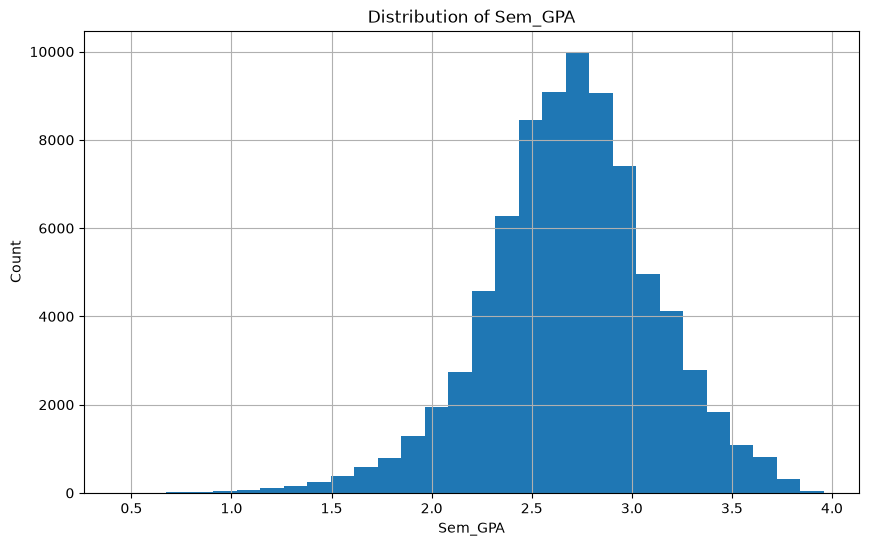

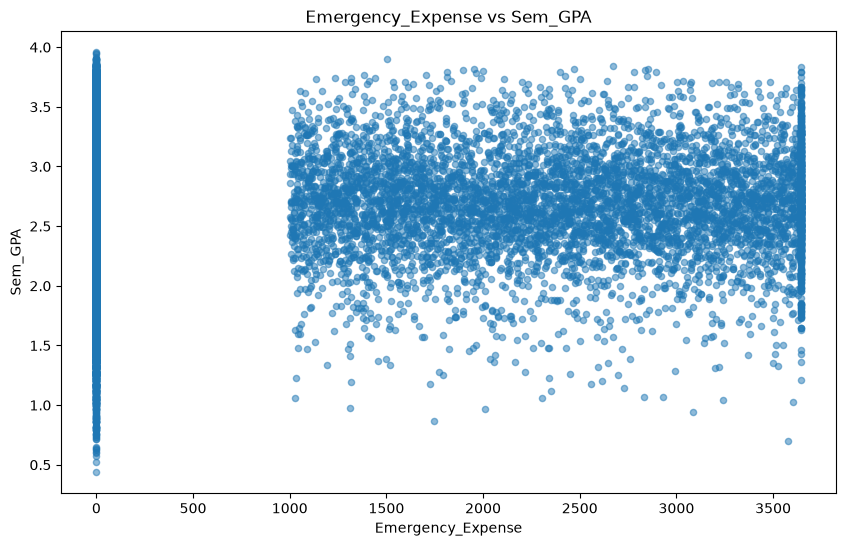

End_of_Semester_Status,Dropped_Out,Enrolled,Graduated
Gender,,,
Female,3471,35213,942
Male,3307,33766,986
Others,97,997,31
Prefer not to say,42,378,9


In [13]:
# Distribution of Sem_GPA
df['Sem_GPA'].hist(bins=30)
plt.title('Distribution of Sem_GPA')
plt.xlabel('Sem_GPA')
plt.ylabel('Count')
plt.show()

# Scatter plot: Emergency_Expense vs Sem_GPA
df.plot.scatter(x='Emergency_Expense', y='Sem_GPA', alpha=0.5)
plt.title('Emergency_Expense vs Sem_GPA')
plt.show()

# End_of_Semester_Status by Gender
pd.crosstab(df['Gender'], df['End_of_Semester_Status'])


In [14]:
# EDA Table 1: Gender Ã— End_of_Semester_Status crosstab with row percentages
t1 = pd.crosstab(df['Gender'], df['End_of_Semester_Status'], margins=True)
t1_pct = t1.div(t1['All'], axis=0).mul(100).round(1)
print('Table 1: Gender Ã— End_of_Semester_Status (% of row)')
print(t1_pct)
print()

# EDA Table 2: Semester Ã— End_of_Semester_Status crosstab
t2 = pd.crosstab(df['Semester'], df['End_of_Semester_Status'], margins=True)
print('Table 2: Semester Ã— End_of_Semester_Status (counts)')
print(t2)
print()

# EDA Table 3: Scholarship Ã— End_of_Semester_Status crosstab with row percentages
t3 = pd.crosstab(df['Scholarship'], df['End_of_Semester_Status'], margins=True)
t3_pct = t3.div(t3['All'], axis=0).mul(100).round(1)
print('Table 3: Scholarship Ã— End_of_Semester_Status (% of row)')
print(t3_pct)
print()

# EDA Table 4: Family_Income binned stats by End_of_Semester_Status
df['Income_Bin'] = pd.qcut(df['Family_Income'], q=4, duplicates='drop')
t4 = df.groupby(['Income_Bin', 'End_of_Semester_Status']).size().unstack(fill_value=0)
t4['Total'] = t4.sum(axis=1)
t4_pct = t4.div(t4['Total'], axis=0).mul(100).round(1)
print('Table 4: Income quartile Ã— End_of_Semester_Status (% of row)')
print(t4_pct)
print()

# EDA Table 5: Summary metrics by Gender
t5 = df.groupby('Gender').agg(
    n_students=('Student_ID', 'nunique'),
    n_rows=('Student_ID', 'size'),
    avg_sem_gpa=('Sem_GPA', 'mean'),
    avg_attendance=('Attendance', 'mean'),
    avg_financial_stress=('Financial_Stress', 'mean'),
    dropout_rate=('Target_Dropout_Next_Sem', 'mean'),
).round(3)
t5['dropout_rate'] = (t5['dropout_rate'] * 100).round(1)
print('Table 5: Summary metrics by Gender')
print(t5)


Table 1: Gender Ã— End_of_Semester_Status (% of row)
End_of_Semester_Status  Dropped_Out  Enrolled  Graduated    All
Gender                                                         
Female                          8.8      88.9        2.4  100.0
Male                            8.7      88.7        2.6  100.0
Others                          8.6      88.6        2.8  100.0
Prefer not to say               9.8      88.1        2.1  100.0
All                             8.7      88.8        2.5  100.0

Table 2: Semester Ã— End_of_Semester_Status (counts)
End_of_Semester_Status  Dropped_Out  Enrolled  Graduated    All
Semester                                                       
1                              1332     18668          0  20000
2                              1473     15123          0  16596
3                              1289     11942          0  13231
4                               950      9289          0  10239
5                               771      6934          0   77

Table 5: Summary metrics by Gender
                   n_students  n_rows  avg_sem_gpa  avg_attendance  \
Gender                                                               
Female                  10012   39626        2.689          85.064   
Male                     9589   38059        2.694          85.105   
Others                    289    1125        2.687          84.822   
Prefer not to say         110     429        2.683          85.271   

                   avg_financial_stress  dropout_rate  
Gender                                                 
Female                            2.580           8.8  
Male                              2.577           8.7  
Others                            2.538           8.6  
Prefer not to say                 2.640           9.8  


Distribution Table A: End_of_Semester_Status
                        Count  Percent
End_of_Semester_Status                
Enrolled                70354     88.8
Dropped_Out              6917      8.7
Graduated                1968      2.5

Distribution Table B: Gender
                   Count  Percent
Gender                           
Female             39626     50.0
Male               38059     48.0
Others              1125      1.4
Prefer not to say    429      0.5

Distribution Table C: Scholarship
             Count  Percent
Scholarship                
0            57249     72.2
1            21990     27.8

Distribution Table D: Semester
          Count  Percent
Semester                
1         20000     25.2
2         16596     20.9
3         13231     16.7
4         10239     12.9
5          7705      9.7
6          5554      7.0
7          3742      4.7
8          2172      2.7


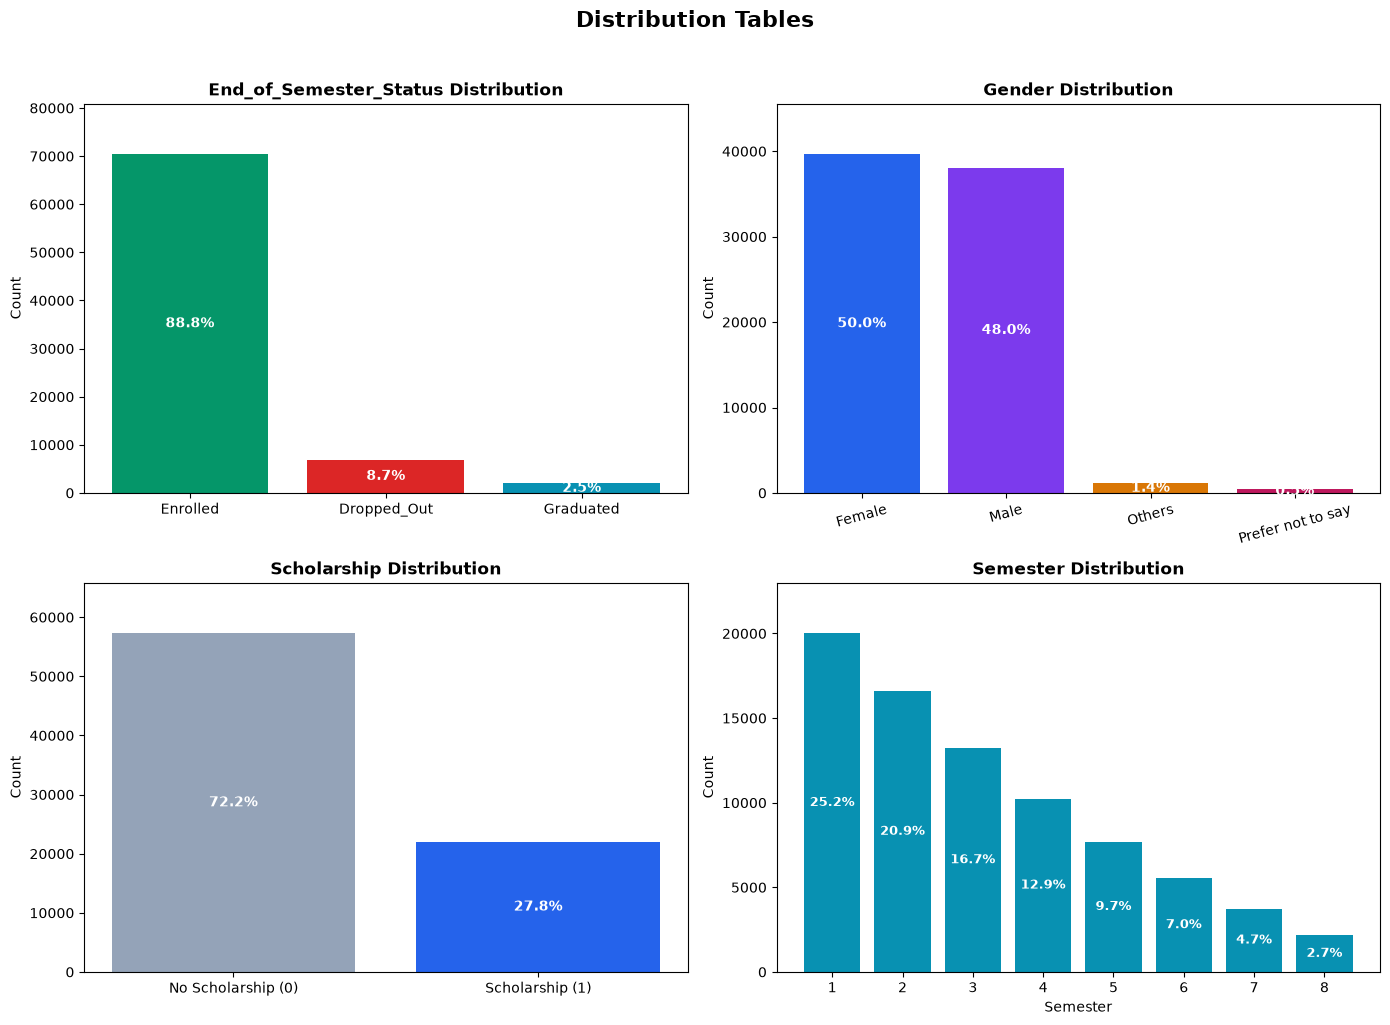

Saved eda_distribution_tables.png


In [15]:
# Distribution Tables (counts & percentages)
dist_status = df['End_of_Semester_Status'].value_counts()
dist_status_pct = (dist_status / len(df) * 100).round(1)
dist_status_df = pd.DataFrame({'Count': dist_status, 'Percent': dist_status_pct})
print('Distribution Table A: End_of_Semester_Status')
print(dist_status_df)
print()

dist_gender = df['Gender'].value_counts()
dist_gender_pct = (dist_gender / len(df) * 100).round(1)
dist_gender_df = pd.DataFrame({'Count': dist_gender, 'Percent': dist_gender_pct})
print('Distribution Table B: Gender')
print(dist_gender_df)
print()

dist_scholarship = df['Scholarship'].value_counts()
dist_scholarship_pct = (dist_scholarship / len(df) * 100).round(1)
dist_scholarship_df = pd.DataFrame({'Count': dist_scholarship, 'Percent': dist_scholarship_pct})
print('Distribution Table C: Scholarship')
print(dist_scholarship_df)
print()

dist_semester = df['Semester'].value_counts().sort_index()
dist_semester_pct = (dist_semester / len(df) * 100).round(1)
dist_semester_df = pd.DataFrame({'Count': dist_semester, 'Percent': dist_semester_pct})
print('Distribution Table D: Semester')
print(dist_semester_df)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Distribution Tables', fontsize=16, weight='bold', y=1.02)

colors_status = {'Enrolled': '#059669', 'Dropped_Out': '#dc2626', 'Graduated': '#0891b2'}
ax = axes[0, 0]
bars = ax.bar(dist_status.index, dist_status.values, color=[colors_status.get(x, '#64748b') for x in dist_status.index])
ax.set_title('End_of_Semester_Status Distribution', weight='bold')
ax.set_ylabel('Count')
for i, (idx, val) in enumerate(dist_status.items()):
    ax.text(i, val/2, f'{dist_status_pct[idx]}%', ha='center', va='center', color='white', weight='bold', fontsize=10)
ax.set_ylim(0, max(dist_status.values) * 1.15)

colors_g = {'Female': '#2563eb', 'Male': '#7c3aed', 'Others': '#d97706', 'Prefer not to say': '#be185d'}
ax = axes[0, 1]
bars = ax.bar(dist_gender.index, dist_gender.values, color=[colors_g.get(x, '#64748b') for x in dist_gender.index])
ax.set_title('Gender Distribution', weight='bold')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=15)
for i, (idx, val) in enumerate(dist_gender.items()):
    ax.text(i, val/2, f'{dist_gender_pct[idx]}%', ha='center', va='center', color='white', weight='bold', fontsize=10)
ax.set_ylim(0, max(dist_gender.values) * 1.15)

ax = axes[1, 0]
labels_scholarship = ['No Scholarship (0)', 'Scholarship (1)']
bars = ax.bar(labels_scholarship, dist_scholarship.values, color=['#94a3b8', '#2563eb'])
ax.set_title('Scholarship Distribution', weight='bold')
ax.set_ylabel('Count')
for i, (idx, val) in enumerate(dist_scholarship.items()):
    ax.text(i, val/2, f'{dist_scholarship_pct[idx]}%', ha='center', va='center', color='white', weight='bold', fontsize=10)
ax.set_ylim(0, max(dist_scholarship.values) * 1.15)

ax = axes[1, 1]
ax.bar(dist_semester.index, dist_semester.values, color='#0891b2')
ax.set_title('Semester Distribution', weight='bold')
ax.set_xlabel('Semester')
ax.set_ylabel('Count')
ax.set_xticks(dist_semester.index)
for i, (idx, val) in enumerate(dist_semester.items()):
    ax.text(idx, val/2, f'{dist_semester_pct[idx]}%', ha='center', va='center', color='white', weight='bold', fontsize=9)
ax.set_ylim(0, max(dist_semester.values) * 1.15)

plt.tight_layout()
plt.savefig('eda_distribution_tables.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_distribution_tables.png')


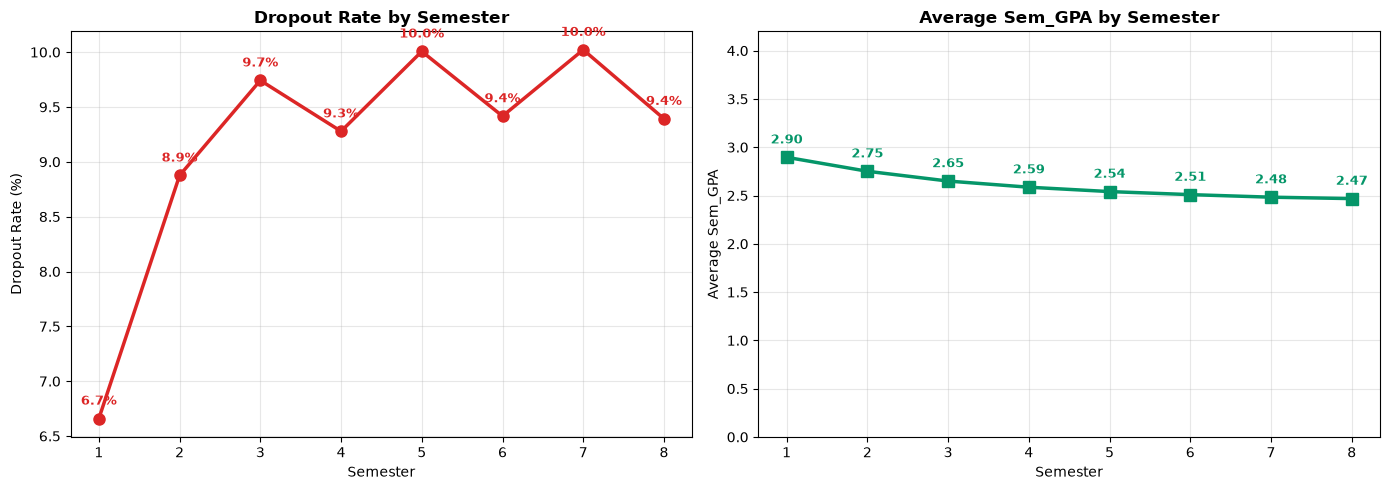

Saved eda_line_charts_trends.png


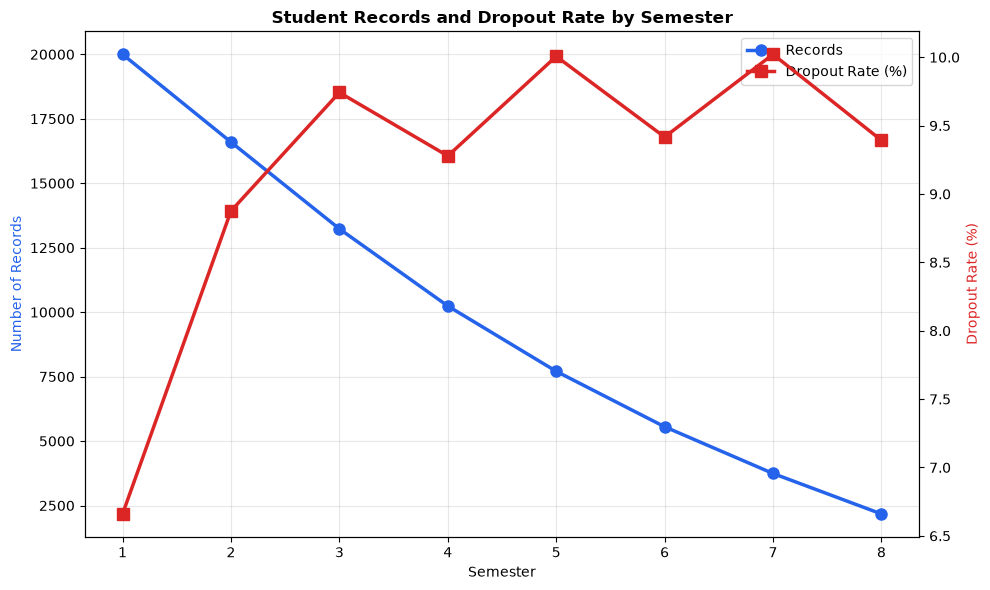

Saved eda_line_chart_enrollment_dropout.png


In [16]:
# Line Charts: trends over semesters
semester_stats = df.groupby('Semester').agg(
    dropout_rate=('Target_Dropout_Next_Sem', 'mean'),
    avg_gpa=('Sem_GPA', 'mean'),
    n=('Student_ID', 'size')
).reset_index()
semester_stats['dropout_rate_pct'] = semester_stats['dropout_rate'] * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.plot(semester_stats['Semester'], semester_stats['dropout_rate_pct'], marker='o', linewidth=2.5, markersize=8, color='#dc2626')
ax.set_title('Dropout Rate by Semester', weight='bold')
ax.set_xlabel('Semester')
ax.set_ylabel('Dropout Rate (%)')
ax.set_xticks(semester_stats['Semester'])
ax.grid(True, alpha=0.3)
for _, row in semester_stats.iterrows():
    ax.annotate(f'{row["dropout_rate_pct"]:.1f}%', (row['Semester'], row['dropout_rate_pct']),
                textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, weight='bold', color='#dc2626')

ax = axes[1]
ax.plot(semester_stats['Semester'], semester_stats['avg_gpa'], marker='s', linewidth=2.5, markersize=8, color='#059669')
ax.set_title('Average Sem_GPA by Semester', weight='bold')
ax.set_xlabel('Semester')
ax.set_ylabel('Average Sem_GPA')
ax.set_xticks(semester_stats['Semester'])
ax.set_ylim(0, 4.2)
ax.grid(True, alpha=0.3)
for _, row in semester_stats.iterrows():
    ax.annotate(f'{row["avg_gpa"]:.2f}', (row['Semester'], row['avg_gpa']),
                textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, weight='bold', color='#059669')

plt.tight_layout()
plt.savefig('eda_line_charts_trends.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_line_charts_trends.png')

fig, ax = plt.subplots(figsize=(10, 6))
ax2 = ax.twinx()
line1 = ax.plot(semester_stats['Semester'], semester_stats['n'], marker='o', linewidth=2.5, markersize=8, color='#2563eb', label='Records')
line2 = ax2.plot(semester_stats['Semester'], semester_stats['dropout_rate_pct'], marker='s', linewidth=2.5, markersize=8, color='#dc2626', label='Dropout Rate (%)')
ax.set_title('Student Records and Dropout Rate by Semester', weight='bold')
ax.set_xlabel('Semester')
ax.set_ylabel('Number of Records', color='#2563eb')
ax2.set_ylabel('Dropout Rate (%)', color='#dc2626')
ax.set_xticks(semester_stats['Semester'])
ax.grid(True, alpha=0.3)
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax.legend(lines, labels, loc='upper right')
plt.tight_layout()
plt.savefig('eda_line_chart_enrollment_dropout.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_line_chart_enrollment_dropout.png')


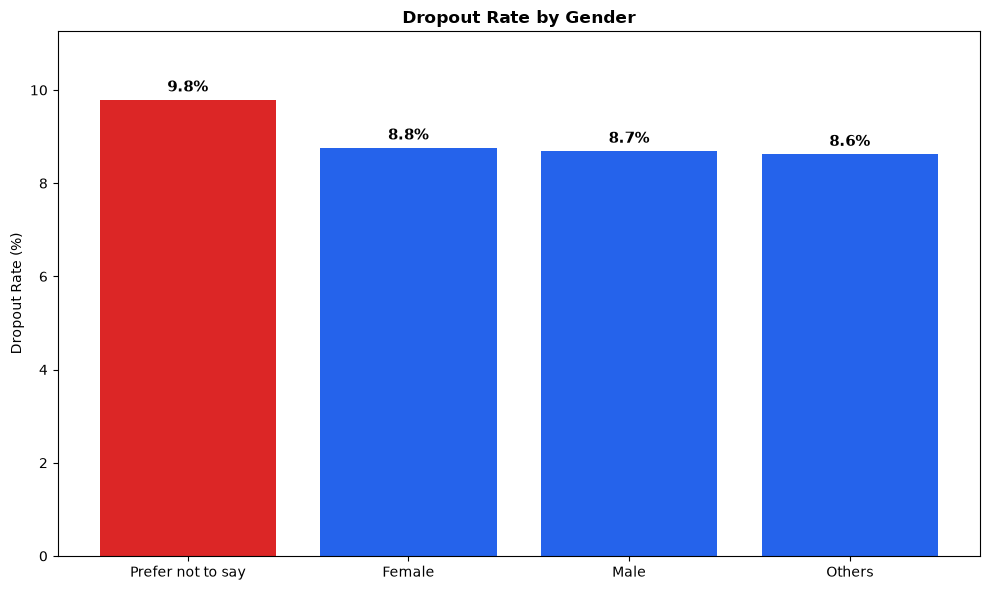

Saved eda_bar_dropout_by_gender.png


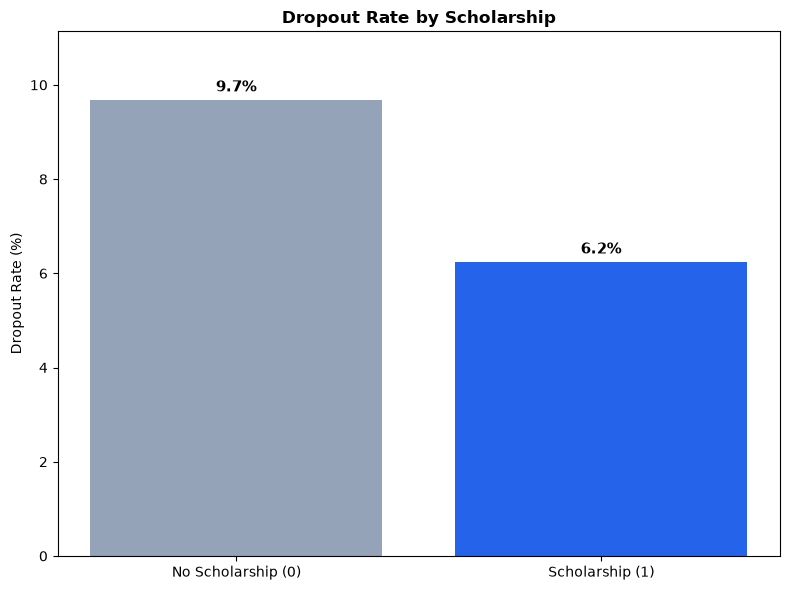

Saved eda_bar_dropout_by_scholarship.png


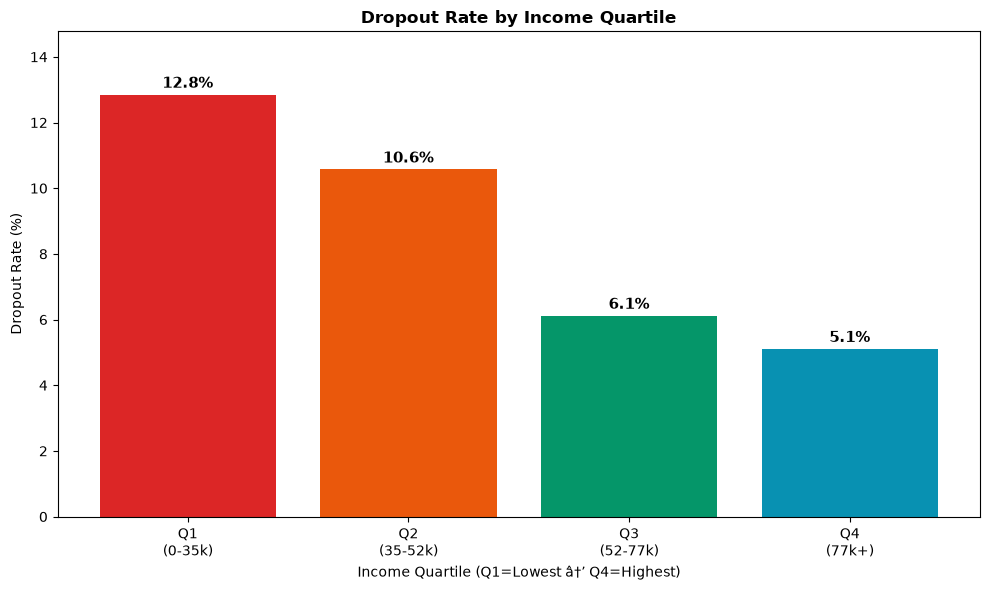

Saved eda_bar_dropout_by_income.png


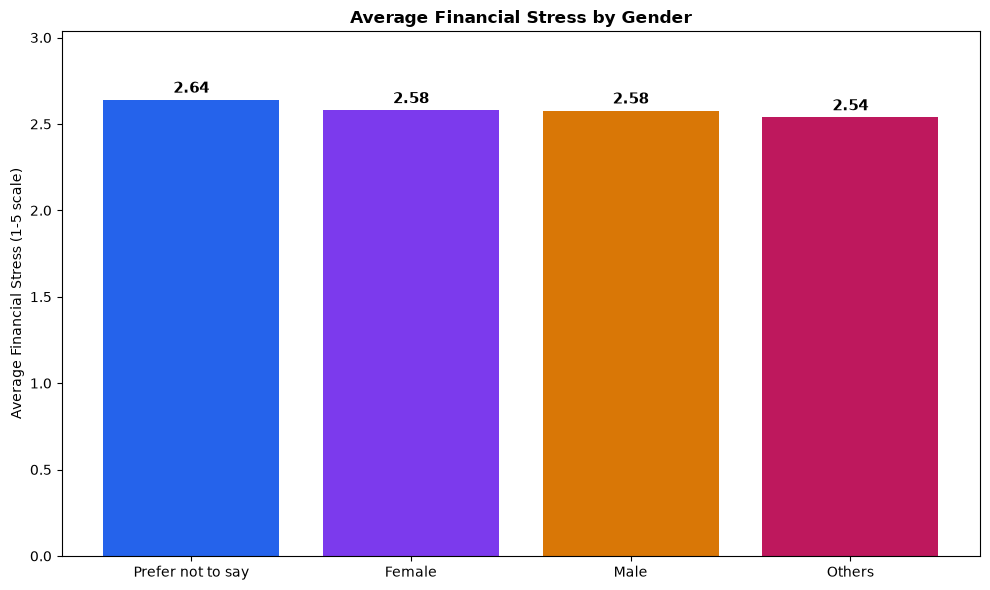

Saved eda_bar_stress_by_gender.png


In [17]:
# Bar Graphs: dropout rate by category
gender_dropout = df.groupby('Gender')['Target_Dropout_Next_Sem'].mean() * 100
gender_dropout = gender_dropout.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
colors_bar1 = ['#dc2626' if v == gender_dropout.max() else '#2563eb' for v in gender_dropout.values]
bars = ax.bar(gender_dropout.index, gender_dropout.values, color=colors_bar1)
ax.set_title('Dropout Rate by Gender', weight='bold')
ax.set_ylabel('Dropout Rate (%)')
ax.set_ylim(0, max(gender_dropout.values) * 1.15)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.1, f'{h:.1f}%', ha='center', va='bottom', fontsize=11, weight='bold')
plt.tight_layout()
plt.savefig('eda_bar_dropout_by_gender.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_bar_dropout_by_gender.png')

scholarship_dropout = df.groupby('Scholarship')['Target_Dropout_Next_Sem'].mean() * 100
scholarship_dropout.index = ['No Scholarship (0)', 'Scholarship (1)']

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(scholarship_dropout.index, scholarship_dropout.values, color=['#94a3b8', '#2563eb'])
ax.set_title('Dropout Rate by Scholarship', weight='bold')
ax.set_ylabel('Dropout Rate (%)')
ax.set_ylim(0, max(scholarship_dropout.values) * 1.15)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.1, f'{h:.1f}%', ha='center', va='bottom', fontsize=11, weight='bold')
plt.tight_layout()
plt.savefig('eda_bar_dropout_by_scholarship.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_bar_dropout_by_scholarship.png')

df['Income_Bin'] = pd.qcut(df['Family_Income'], q=4, duplicates='drop')
income_dropout = df.groupby('Income_Bin')['Target_Dropout_Next_Sem'].mean() * 100

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(range(len(income_dropout)), income_dropout.values, color=['#dc2626', '#ea580c', '#059669', '#0891b2'])
ax.set_title('Dropout Rate by Income Quartile', weight='bold')
ax.set_ylabel('Dropout Rate (%)')
ax.set_xlabel('Income Quartile (Q1=Lowest â†’ Q4=Highest)')
ax.set_xticks(range(len(income_dropout)))
ax.set_xticklabels(['Q1\n(0-35k)', 'Q2\n(35-52k)', 'Q3\n(52-77k)', 'Q4\n(77k+)'], fontsize=10)
ax.set_ylim(0, max(income_dropout.values) * 1.15)
for i, bar in enumerate(bars):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.1, f'{h:.1f}%', ha='center', va='bottom', fontsize=11, weight='bold')
plt.tight_layout()
plt.savefig('eda_bar_dropout_by_income.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_bar_dropout_by_income.png')

gender_stress = df.groupby('Gender')['Financial_Stress'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(gender_stress.index, gender_stress.values, color=['#2563eb', '#7c3aed', '#d97706', '#be185d'])
ax.set_title('Average Financial Stress by Gender', weight='bold')
ax.set_ylabel('Average Financial Stress (1-5 scale)')
ax.set_ylim(0, max(gender_stress.values) * 1.15)
for bar in bars:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.02, f'{h:.2f}', ha='center', va='bottom', fontsize=11, weight='bold')
plt.tight_layout()
plt.savefig('eda_bar_stress_by_gender.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved eda_bar_stress_by_gender.png')


In [18]:
# Save cleaned data
df.to_csv('academic_survival_longitudinal_cleaned.csv', index=False)
print('Saved cleaned data to academic_survival_longitudinal_cleaned.csv')
print('Final shape:', df.shape)


Saved cleaned data to academic_survival_longitudinal_cleaned.csv
Final shape: (79239, 24)


## Next steps

- Confirm `academic_survival_longitudinal (1).csv` is in this folder before running.
- Install dependencies: `conda install pandas matplotlib`
- Review invalid Sem_GPA rows flagged in the cleaning cell.
- Adjust outlier capping / imputation strategy as needed.
- Add statistical tests or survival modeling using `Censored` and `Target_Dropout_Next_Sem`.
